In [61]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df=pd.read_csv('drug.csv')
print(df.head())
print(df.tail())
print(df.info())
print(df.shape)
print(df.columns)


   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  DrugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  DrugY
     Age Sex      BP Cholesterol  Na_to_K   Drug
195   56   F     LOW        HIGH   11.567  drugC
196   16   M     LOW        HIGH   12.006  drugC
197   52   M  NORMAL        HIGH    9.894  drugX
198   23   M  NORMAL      NORMAL   14.020  drugX
199   40   F     LOW      NORMAL   11.349  drugX
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str

In [63]:
print(df.describe())

              Age     Na_to_K
count  200.000000  200.000000
mean    44.315000   16.084485
std     16.544315    7.223956
min     15.000000    6.269000
25%     31.000000   10.445500
50%     45.000000   13.936500
75%     58.000000   19.380000
max     74.000000   38.247000


In [64]:
print("null values ",df.isnull().sum().sum())
print("duplicate values" ,df.duplicated().sum())

null values  0
duplicate values 0


In [ ]:
categorical_columns=df.select_dtypes(include='str')
numerical_columns=df.select_dtypes(include='number')

In [66]:
for i in categorical_columns:
    print(i,df[i].unique())

Sex <StringArray>
['F', 'M']
Length: 2, dtype: str
BP <StringArray>
['HIGH', 'LOW', 'NORMAL']
Length: 3, dtype: str
Cholesterol <StringArray>
['HIGH', 'NORMAL']
Length: 2, dtype: str
Drug <StringArray>
['DrugY', 'drugC', 'drugX', 'drugA', 'drugB']
Length: 5, dtype: str


In [67]:
for i in numerical_columns:
    print(i,df[i].unique())

Age [23 47 28 61 22 49 41 60 43 34 74 50 16 69 32 57 63 48 33 31 39 45 18 65
 53 46 15 73 58 66 37 68 67 62 24 26 40 38 29 17 54 70 36 19 64 59 51 42
 56 20 72 35 52 55 30 21 25]
Na_to_K [25.355 13.093 10.114  7.798 18.043  8.607 16.275 11.037 15.171 19.368
 11.767 19.199 15.376 20.942 12.703 15.516 11.455 13.972  7.298 25.974
 19.128 25.917 30.568 15.036 33.486 18.809 30.366  9.381 22.697 17.951
  8.75   9.567 11.014 31.876 14.133  7.285  9.445 13.938  9.709  9.084
 19.221 14.239 15.79  12.26  12.295  8.107 13.091 10.291 31.686 19.796
 19.416 10.898 27.183 18.457 10.189 14.16  11.34  27.826 10.091 18.703
 29.875  9.475 20.693  8.37  13.303 27.05  12.856 10.832 24.658 24.276
 13.967 19.675 10.605 22.905 17.069 20.909 11.198 19.161 13.313 10.84
 13.934  7.761  9.712 11.326 10.067 13.935 13.597 15.478 23.091 17.211
 16.594 15.156 29.45  29.271 15.015 11.424 38.247 25.395 35.639 16.725
 11.871 12.854 13.127  8.966 28.294  8.968 11.953 20.013  9.677 16.85
  7.49   6.683  9.17  13.769  9.28

In [68]:
mapping = {
    'DrugY': 'DrugY',
    'drugC': 'DrugC',
    'drugX': 'DrugX',
    'drugA': 'DrugA',
    'drugB': 'DrugB'
}

df['Drug'] = df['Drug'].replace(mapping)

print(df['Drug'].unique())

<StringArray>
['DrugY', 'DrugC', 'DrugX', 'DrugA', 'DrugB']
Length: 5, dtype: str


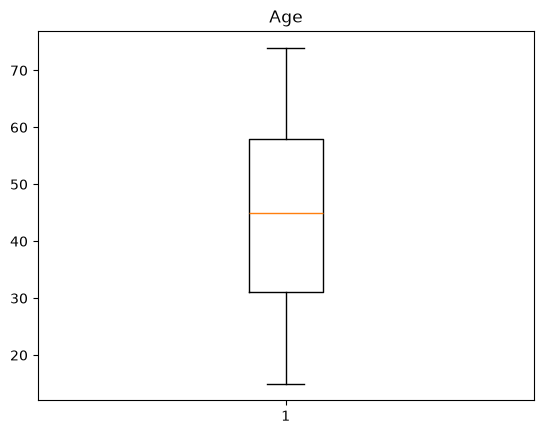

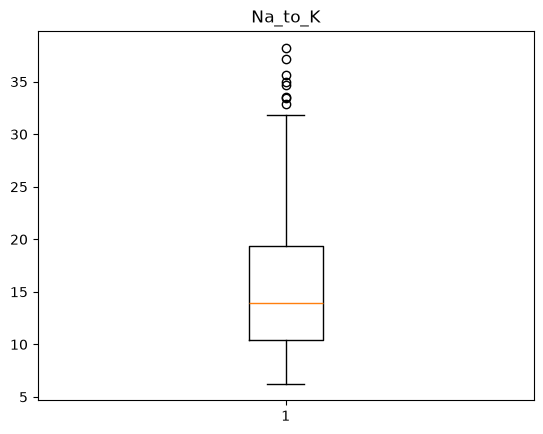

In [69]:
for i in numerical_columns:
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

In [70]:
q1=df['Na_to_K'].quantile(0.25)
q3=df['Na_to_K'].quantile(0.75)
IQR=q3-q1
lower=q1-1.5*IQR
upper=q3+1.5*IQR
outliers=df[(df['Na_to_K']>upper)|(df['Na_to_K']<lower)]



In [71]:
numerical_columns.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [72]:
print("Age Skewness = ",df['Age'].skew())
print("Na_to_K = ",df['Na_to_K'].skew())

Age Skewness =  0.030308357030005638
Na_to_K =  1.0393411860288815


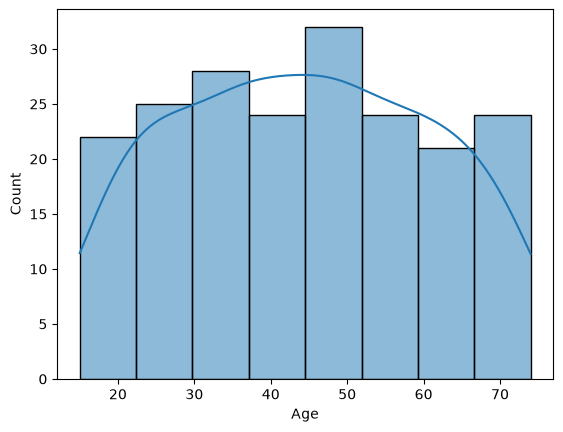

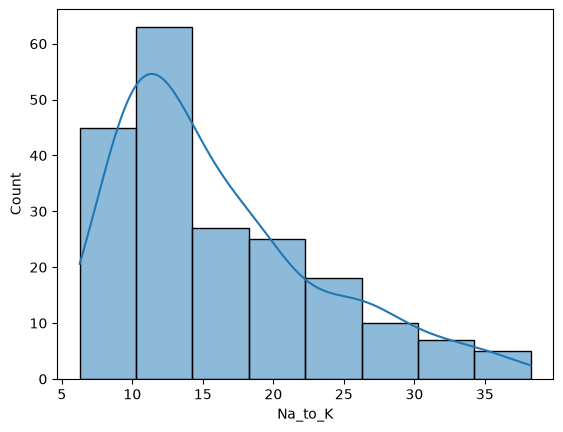

In [73]:
for i in numerical_columns:
    sns.histplot(
        data=df,
        x=df[i],
        bins=8,
        kde=True
    )
    plt.show()

In [76]:
for i in categorical_columns:
    print(df[i].value_counts())

Sex
M    104
F     96
Name: count, dtype: int64
BP
HIGH      77
LOW       64
NORMAL    59
Name: count, dtype: int64
Cholesterol
HIGH      103
NORMAL     97
Name: count, dtype: int64
Drug
DrugY    91
DrugX    54
DrugA    23
DrugC    16
DrugB    16
Name: count, dtype: int64


In [56]:
for i in categorical_columns:
    print(i,df[i].value_counts()*100/len(df[i]))

Sex Sex
F    55.172414
M    44.827586
Name: count, dtype: float64
BP BP
HIGH      50.000000
NORMAL    32.758621
LOW       17.241379
Name: count, dtype: float64
Cholesterol Cholesterol
HIGH      51.724138
NORMAL    48.275862
Name: count, dtype: float64
Drug Drug
DrugY    46.551724
DrugX    25.862069
DrugA    17.241379
DrugC    10.344828
Name: count, dtype: float64


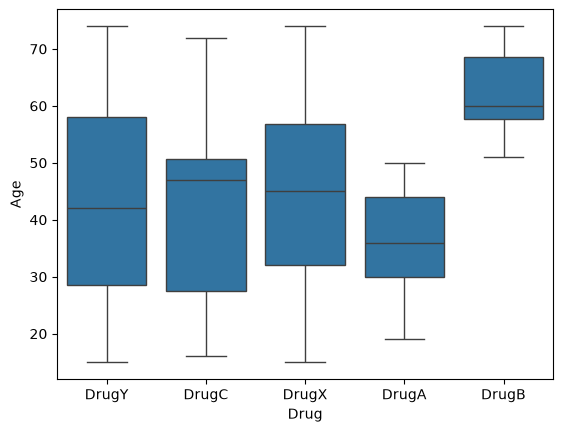

In [87]:
sns.boxplot(data=df,x='Drug',y='Age')
plt.show()

In [84]:
print(df.groupby('Drug')['Age'].mean())
print(df.groupby('Drug')['Age'].median())


Drug
DrugA    35.869565
DrugB    62.500000
DrugC    42.500000
DrugX    44.018519
DrugY    43.747253
Name: Age, dtype: float64
Drug
DrugA    36.0
DrugB    60.0
DrugC    47.0
DrugX    45.0
DrugY    42.0
Name: Age, dtype: float64


<Axes: xlabel='Drug', ylabel='count'>

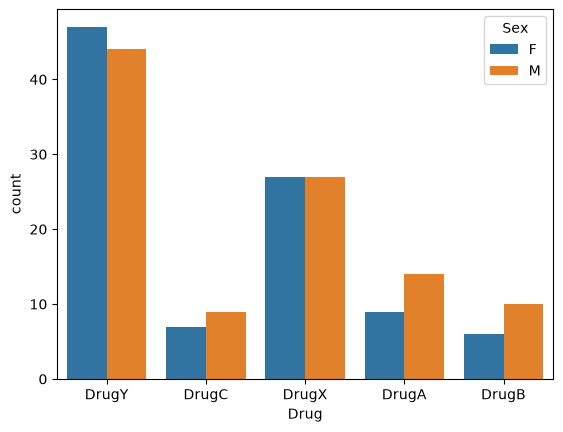

In [94]:
sns.countplot(data=df,x='Drug',hue='Sex')

In [90]:
df.groupby('Drug')['Sex'].value_counts()

Drug   Sex
DrugA  M      14
       F       9
DrugB  M      10
       F       6
DrugC  M       9
       F       7
DrugX  F      27
       M      27
DrugY  F      47
       M      44
Name: count, dtype: int64

In [97]:
cross_tab = pd.crosstab(df["Sex"], df["Drug"])
print(cross_tab)

Drug  DrugA  DrugB  DrugC  DrugX  DrugY
Sex                                    
F         9      6      7     27     47
M        14     10      9     27     44


In [ ]:
percentages_by_sex = (
    pd.crosstab(df["Sex"], df["Drug"], normalize="index") * 100
)
print(percentages_by_sex.round(2).astype(str) + "%")


--- Percentages by Sex (Row Normalized) ---
Drug   DrugA  DrugB  DrugC   DrugX   DrugY
Sex                                       
F      9.38%  6.25%  7.29%  28.12%  48.96%
M     13.46%  9.62%  8.65%  25.96%  42.31%


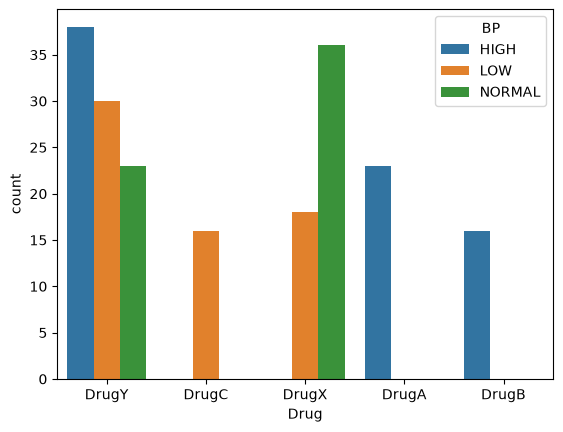

In [100]:
sns.countplot(data=df,x='Drug',hue='BP')
plt.show()

In [134]:
bp_corss=pd.crosstab(df['BP'],df['Drug'])
print("drug and bp")
print(bp_corss)

drug and bp
Drug    DrugA  DrugB  DrugC  DrugX  DrugY
BP                                       
HIGH       23     16      0      0     38
LOW         0      0     16     18     30
NORMAL      0      0      0     36     23


In [135]:
bp_cross = (
    pd.crosstab(df["Drug"], df["BP"], normalize="index") * 100
)
print(bp_corss.round(2).astype(str) + "%")

Drug   DrugA DrugB DrugC DrugX DrugY
BP                                  
HIGH     23%   16%    0%    0%   38%
LOW       0%    0%   16%   18%   30%
NORMAL    0%    0%    0%   36%   23%


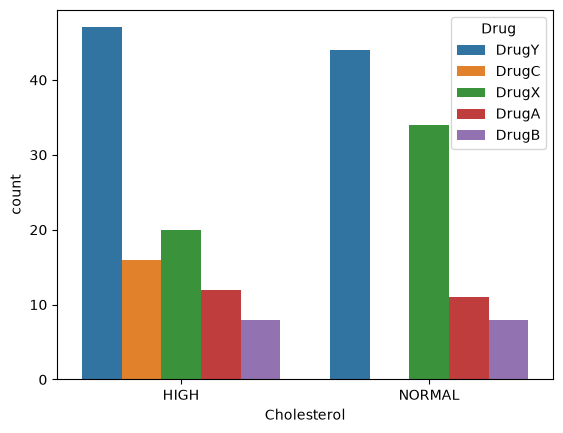

In [133]:
sns.countplot(data=df,x='Cholesterol',hue='Drug')
plt.show()

In [136]:
cholestrol_corss=pd.crosstab(df['Cholesterol'],df['Drug'])
print(cholestrol_corss)

Drug         DrugA  DrugB  DrugC  DrugX  DrugY
Cholesterol                                   
HIGH            12      8     16     20     47
NORMAL          11      8      0     34     44


In [137]:
cholestrol_corss=pd.crosstab(df['Cholesterol'],df['Drug'],normalize="index")*100
print(cholestrol_corss.round(2).astype(str)+"%")

Drug          DrugA  DrugB   DrugC   DrugX   DrugY
Cholesterol                                       
HIGH         11.65%  7.77%  15.53%  19.42%  45.63%
NORMAL       11.34%  8.25%    0.0%  35.05%  45.36%


[]

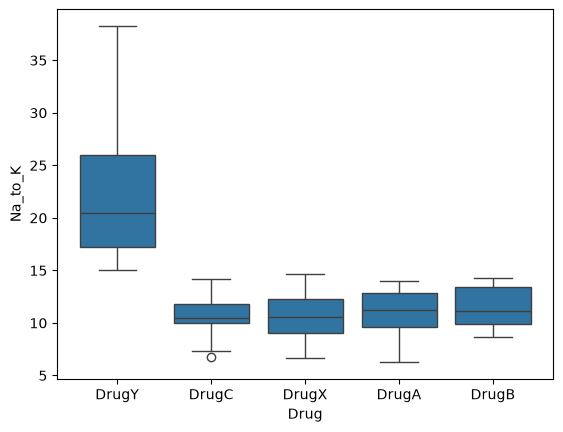

In [131]:
sns.boxplot(data=df,x='Drug',y='Na_to_K')
plt.plot()



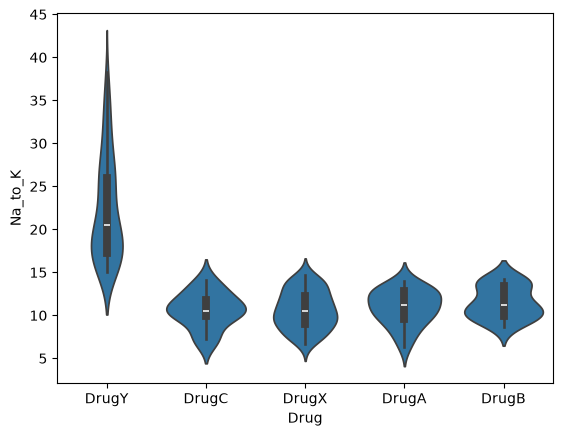

In [132]:
sns.violinplot(data=df,x='Drug',y='Na_to_K')
plt.show()

In [115]:
df.groupby('Drug')['Na_to_K'].agg(['mean','median'])

,mean,median
Drug,,
DrugA,10.918783,11.2270
DrugB,11.524375,11.1745
DrugC,10.633750,10.4905
DrugX,10.650556,10.5240
DrugY,22.374780,20.4890


In [124]:
correlation=df.select_dtypes(include='number').corr()
correlation

,Age,Na_to_K
Age,1.000000,-0.063119
Na_to_K,-0.063119,1.000000


<Axes: xlabel='Age', ylabel='Na_to_K'>

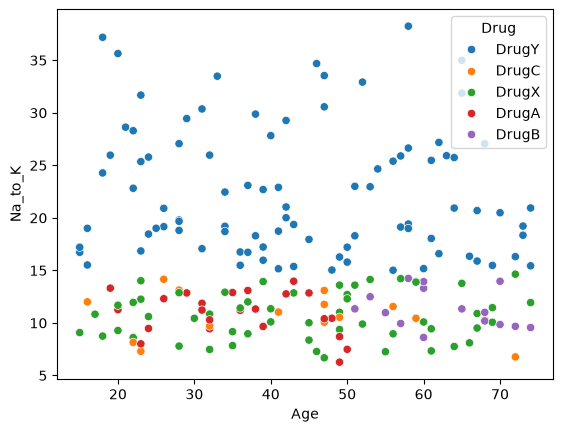

In [126]:
sns.scatterplot(data=df, x="Age", y="Na_to_K", hue="Drug", )

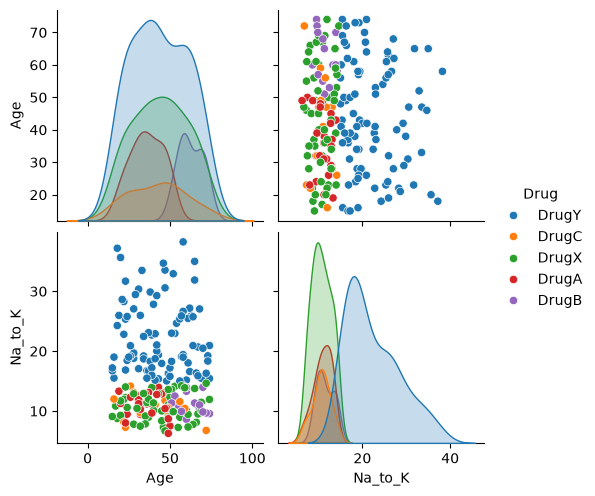

In [130]:
sns.pairplot(data=df,hue='Drug')